# 04 · Combinations: can decision models add to TimesFM?

`03_enrichment` found that no added information makes any model beat the random walk, and that decision models forecast worse when they read headlines themselves. This notebook tests the two roles left for them:

1. **Combining forecasts.** Averaging a decision model's forecast with TimesFM's, or trusting TimesFM only when a decision model agrees with it. This needs no new forecasts: it reuses those of 03.
2. **Reading instead of forecasting.** Asking a decision model only how good or bad each headline is for an instrument's price, turning the answers into a daily news score, and measuring whether that score predicts returns before using it anywhere.

Both are judged as in 02 and 03: against the random walk and against TimesFM alone, on the same decision points, with paired bootstrap intervals.

## Setup

In [10]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from sbench import combine, plots
from sbench.backtest import decision_points, load_results
from sbench.context import NewsFeed
from sbench.headlines import HeadlineReader, read_all
from sbench.panel import ASSET_CLASS, load_panel
from sbench.scoring import per_forecast, rank_ic, skill_table

os.environ.setdefault("HF_HUB_OFFLINE", "1")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SNAPSHOTS = ROOT / "data" / "snapshots"
RESULTS_03 = ROOT / "data" / "results" / "03_enrichment"   # forecasts reused in part 1
RESULTS = ROOT / "data" / "results" / "04_combinations"    # headline readings; committed
CHARTS = ROOT / "outputs" / "04_combinations"              # regenerated; not committed

SCORE_START, CHECK_START, END = "2024-01-01", "2026-03-01", "2026-09-30"
FIT_END = pd.Timestamp("2026-01-01")   # part 1: weights fitted before, scored from this date
HORIZON, STEP, MIN_HISTORY = 5, 5, 100
TFM = "timesfm3"

plots.use_style()
pd.set_option("display.float_format", "{:.3f}".format)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

## Part 1: combining forecasts

The forecasts are those of 03 at horizon 5 (price-only and indicator states). Two kinds of combination:

- **Linear pool:** at every threshold, P(above) = w · TimesFM + (1 − w) · decision model. The weight w is fitted on 2024–2025 (minimising mean CRPS, or Brier on P(up) for lev's direction-only answers), and the pool is scored only on January to September 2026, so the fitted weight never sees the scoring period. An equal-weight pool, which needs no fitting, is shown alongside.
- **Agreement gate:** TimesFM's forecast where TimesFM and the decision model lean the same way on direction, the random walk's elsewhere. The gated forecast is scored on *every* decision point: scoring TimesFM only where the models agree would look better simply by choosing the points.

In [2]:
r03 = pd.concat([load_results(RESULTS_03 / f"{f}.csv") for f in ("price", "indicators")], ignore_index=True)
r03 = r03[r03["horizon"] == HORIZON]
fit, test = r03[r03["t"] < FIT_END], r03[r03["t"] >= FIT_END]

MEMBERS = {   # decision model: metric the pool weight is fitted on
    "clef/threshold_noul": "crps_n", "clef/threshold_noul+indicators": "crps_n",
    "kev-9b/threshold_noul+indicators": "crps_n", "lev/direction_choice": "brier_up",
}
combos, fitted, gates = [], [], []
for dm, metric in MEMBERS.items():
    w, curve = combine.fit_pool_weight(fit, TFM, dm, metric=metric)
    fitted.append({"decision model": dm, "metric": metric, "weight on TimesFM": w,
                   "TimesFM alone (2024-2025)": curve.iloc[-1], "fitted pool (2024-2025)": curve.min()})
    combos += [combine.linear_pool(test, {TFM: w, dm: 1 - w}, f"pool: {dm} (fitted)"),
               combine.linear_pool(test, {TFM: 0.5, dm: 0.5}, f"pool: {dm} (equal)")]
for dm in ("clef/threshold_noul", "clef/threshold_noul+indicators", "lev/direction_choice"):
    g = combine.agreement_gate(test, TFM, dm, "random_walk", f"gate: {dm}")
    gates.append({"decision model": dm, "share of points where TimesFM is used": g.groupby(["series", "t"])["gate"].first().mean()})
    combos.append(g.drop(columns="gate"))
display(pd.DataFrame(fitted).set_index("decision model"))
display(pd.DataFrame(gates).set_index("decision model"))

per1 = per_forecast(pd.concat([test, *combos], ignore_index=True))
per1 = per1[per1["predictor"].isin([TFM, "empirical", "random_walk", *MEMBERS]) | per1["predictor"].str.contains(": ")]
print(f"scored on {per1.loc[per1['predictor'] == TFM, 't'].count()} decision points, "
      f"{per1['t'].min():%Y-%m-%d} to {per1['t'].max():%Y-%m-%d}")

,metric,weight on TimesFM,TimesFM alone (2024-2025),fitted pool (2024-2025)
decision model,,,,
clef/threshold_noul,crps_n,0.650,0.603,0.598
clef/threshold_noul+indicators,crps_n,0.600,0.603,0.596
kev-9b/threshold_noul+indicators,crps_n,0.700,0.603,0.598
lev/direction_choice,brier_up,0.550,0.255,0.251


,share of points where TimesFM is used
decision model,
clef/threshold_noul,0.540
clef/threshold_noul+indicators,0.497
lev/direction_choice,0.571


scored on 324 decision points, 2026-01-05 to 2026-09-22


### Against the random walk and against TimesFM alone

In [3]:
def vs(per: pd.DataFrame, baseline: str) -> pd.DataFrame:
    out = []
    for metric, label in (("crps_n", "crps"), ("brier_up", "brier_up")):
        d = per.dropna(subset=[metric])
        sk = skill_table(d[d["predictor"].isin(d["predictor"].unique())], metric, baseline=baseline)
        out.append(sk.set_index("predictor")[["skill", "lo", "hi"]].add_prefix(f"{label}_"))
    return out[0].join(out[1], how="outer")


display(Markdown("**Skill against the random walk**"))
display(vs(per1, "random_walk").sort_values("crps_skill", ascending=False))
display(Markdown("**Skill against TimesFM alone** (> 0 = the combination improves on TimesFM)"))
vs_tfm = vs(per1[per1["predictor"].str.contains(": ") | (per1["predictor"] == TFM)], TFM)
vs_tfm

**Skill against the random walk**

,crps_skill,crps_lo,crps_hi,brier_up_skill,brier_up_lo,brier_up_hi
predictor,,,,,,
pool: clef/threshold_noul+indicators (fitted),0.002,-0.016,0.020,-0.000,-0.026,0.025
pool: kev-9b/threshold_noul+indicators (fitted),0.001,-0.017,0.018,-0.002,-0.026,0.023
pool: clef/threshold_noul+indicators (equal),0.001,-0.017,0.018,-0.000,-0.025,0.026
gate: clef/threshold_noul+indicators,-0.000,-0.017,0.015,-0.011,-0.036,0.013
timesfm3,-0.001,-0.023,0.020,-0.011,-0.044,0.023
gate: clef/threshold_noul,-0.002,-0.018,0.014,-0.013,-0.040,0.012
pool: clef/threshold_noul (fitted),-0.003,-0.021,0.013,-0.011,-0.038,0.015
pool: kev-9b/threshold_noul+indicators (equal),-0.004,-0.020,0.014,-0.002,-0.025,0.020
gate: lev/direction_choice,-0.005,-0.021,0.010,-0.009,-0.037,0.018


**Skill against TimesFM alone** (> 0 = the combination improves on TimesFM)

,crps_skill,crps_lo,crps_hi,brier_up_skill,brier_up_lo,brier_up_hi
predictor,,,,,,
gate: clef/threshold_noul,-0.001,-0.016,0.014,-0.001,-0.025,0.023
gate: clef/threshold_noul+indicators,0.001,-0.013,0.015,0.000,-0.023,0.023
gate: lev/direction_choice,-0.004,-0.020,0.012,0.002,-0.019,0.023
pool: clef/threshold_noul (equal),-0.007,-0.022,0.006,-0.005,-0.032,0.020
pool: clef/threshold_noul (fitted),-0.002,-0.012,0.007,-0.000,-0.018,0.017
pool: clef/threshold_noul+indicators (equal),0.002,-0.012,0.015,0.011,-0.014,0.034
pool: clef/threshold_noul+indicators (fitted),0.003,-0.008,0.014,0.011,-0.011,0.030
pool: kev-9b/threshold_noul+indicators (equal),-0.002,-0.016,0.010,0.009,-0.018,0.035
pool: kev-9b/threshold_noul+indicators (fitted),0.002,-0.005,0.010,0.009,-0.007,0.025


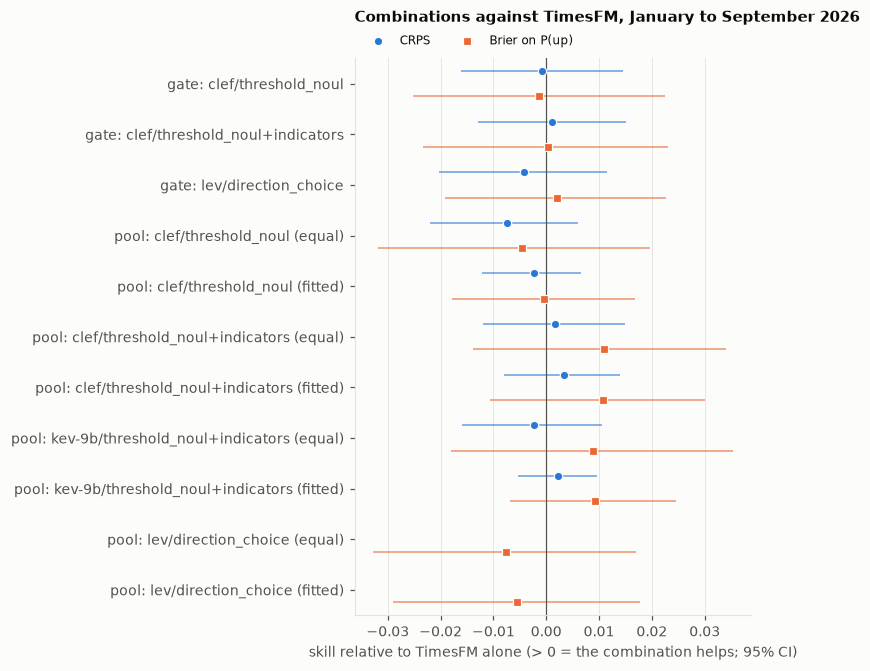

In [4]:
gain = (vs_tfm.reset_index().melt(id_vars="predictor", value_vars=["crps_skill", "brier_up_skill"], var_name="metric",
                                  value_name="skill")
        .assign(lo=lambda d: [vs_tfm.loc[p, m.replace("skill", "lo")] for p, m in zip(d["predictor"], d["metric"])],
                hi=lambda d: [vs_tfm.loc[p, m.replace("skill", "hi")] for p, m in zip(d["predictor"], d["metric"])],
                metric=lambda d: d["metric"].map({"crps_skill": "CRPS", "brier_up_skill": "Brier on P(up)"}))
        .dropna(subset=["skill"]))
plots.dot_plot(gain, y="predictor", x="skill", hue="metric", lo="lo", hi="hi",
               xlabel="skill relative to TimesFM alone (> 0 = the combination helps; 95% CI)",
               title="Combinations against TimesFM, January to September 2026", path=CHARTS / "01_combinations.png");

### Do the models disagree?

Combining can only help if the members' forecasts differ. The correlation of P(up) between predictors over all 2024–2026 decision points:

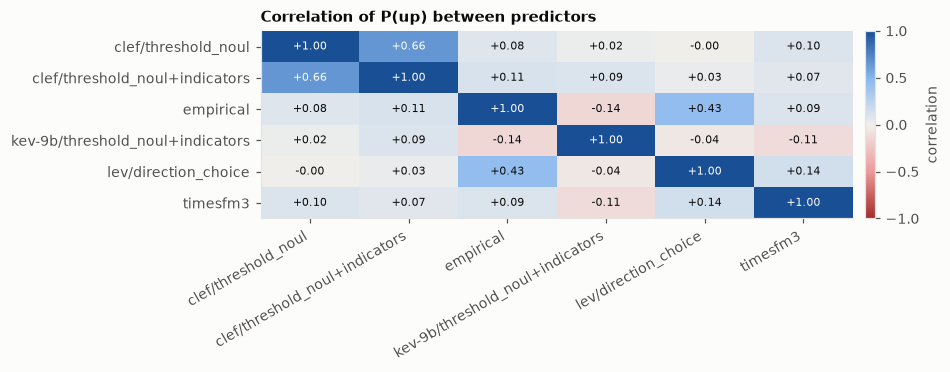

In [5]:
p_up = per_forecast(r03[r03["predictor"].isin([TFM, "empirical", *MEMBERS])]).pivot_table(
    index=["series", "t"], columns="predictor", values="p_up")
plots.heatmap(p_up.corr(), span=1, title="Correlation of P(up) between predictors", cbar_label="correlation",
              path=CHARTS / "02_p_up_correlation.png");

### Part 1 conclusions

**Combinations add nothing measurable to TimesFM.** On the 324 decision points from January to September 2026, the best pool (TimesFM with clef in the indicator state, weight 0.60 on TimesFM fitted on 2024–2025) improves on TimesFM alone by +0.003 in CRPS (interval −0.007 to +0.013) and +0.011 in Brier on P(up) (−0.009 to +0.030). Every other pool and every agreement gate is within ±0.01 of TimesFM, with intervals that include zero. On the fitting period itself the best pool gained under 1% in CRPS over TimesFM alone.

**The models do disagree; none has skill to contribute.** TimesFM's P(up) correlates only weakly with any decision model's (at most about 0.14), so the members are diverse, which is the condition for a pool to help. A pool averages members' errors away, but it cannot create skill none of them has: with every member at or below the random walk, the average sits close to the best member, TimesFM.

**Gating does not select better points.** Using TimesFM only where a decision model agrees with it, and the random walk elsewhere, scores the same as TimesFM everywhere: agreement with these models carries no information about when TimesFM is right.

The test period is short (nine months, 324 points), so these intervals exclude large gains, not small ones.

## Part 2: decision models as headline readers

In 03 the decision models forecast from headlines and became confident in the direction of the news, wrongly. Here they are asked a narrower question they may be better at, and leave forecasting out:

- **The question.** For each of the instrument's 15 newest headlines from the last 24 hours (the same ones 03's news state showed): *"for the price of [instrument], how good or bad is this news?"*, on five levels: bad, slightly bad, no effect or unrelated, slightly good, good. The state holds the numbered headlines only, with no prices and no dates. One question per headline keeps a call short.
- **The news score.** Each headline's expected rating (−1 to +1), averaged over the headlines of a decision point.
- **The test.** The information coefficient (IC): the rank correlation between the news score and the return over the following horizon, pooled over instruments, with a bootstrap interval that resamples dates (so moves shared across instruments on one day are not counted as independent). GDELT's own tone and coverage are the baselines. If the news score has no IC, it cannot help TimesFM as a covariate, and the test stops there.
- **Windows.** Horizon 1 from March 2026, after the decision models' release, is the main window; horizon 5 over 2024–2026 is reported as an upper bound, as in 03.
- **Readers:** lev and clef.

**Expectation, stated before the run.** Studies of language-model headline sentiment (e.g. Lopez-Lira and Tang, 2023) find next-day predictability mainly in small, thinly covered stocks, from news released after the close. Here the instruments are among the most liquid in the world and every headline was published before the decision time, so the price should already reflect it: the expected IC is close to zero.

In [6]:
SERIES = load_panel(SNAPSHOTS)
BY_KEY = {s.key: s for s in SERIES}
FEED = NewsFeed.load(SNAPSHOTS / "03_enrichment" / "news")
NEWS_LABELS = {"BTC": "Bitcoin", "ETH": "Ether", "SPY": "US stocks", "AAPL": "Apple", "GLD": "gold",
               "USO": "oil", "EURUSD": "the euro", "USDJPY": "the yen"}
POINTS = {   # horizon: decision points per instrument, as in 03
    1: {s.key: decision_points(s, 1, min_history=MIN_HISTORY, step=1, start=CHECK_START) for s in SERIES},
    HORIZON: {s.key: decision_points(s, HORIZON, min_history=MIN_HISTORY, step=STEP, start=SCORE_START) for s in SERIES},
}


def requests(horizon: int) -> list[tuple[str, pd.Timestamp]]:
    return [(s.key, pd.Timestamp(s.available_at()[i])) for s in SERIES for i in POINTS[horizon][s.key]]


def titles(key: str, until: pd.Timestamp) -> list[str]:
    return FEED.headlines_at(key, until, FEED.max_headlines)["title"].tolist()


# what one reading looks like (USO on 10 March 2026, during the oil spike; first five headlines)
example = HeadlineReader("lev").read(titles("USO", BY_KEY["USO"].available_at()[
    int(BY_KEY["USO"].df.index[BY_KEY["USO"].df["t"] == "2026-03-10"][0])])[:5], "oil")
example[["title", "rating"]]

,title,rating
0,"Oil plunges, stocks rise as Trump says Iran wa...",-0.324
1,Asian stock markets slide after oil prices spi...,-0.102
2,Oil prices are falling — gas prices aren't. He...,-0.023
3,Russia's shadow fleet militarized: Wagner vete...,-0.122
4,"Iran news: Oil reserves not yet released, G7 m...",-0.044


### Reading the headlines

One call per decision point and reader (about 2,500 per reader: horizon 1 and horizon 5 points); readings are stored with their headlines in `data/results/04_combinations/` and the run resumes where it stopped. At warm speeds this takes well under an hour for lev and a few hours for clef.

In [7]:
READERS = ["lev", "clef"]
asked = list(dict.fromkeys(requests(1) + requests(HORIZON)))
scores = {}
for model in READERS:
    try:
        scores[model] = read_all(HeadlineReader(model), asked, titles, NEWS_LABELS,
                                 RESULTS / f"headline_reads_{model.replace('/', '_')}.jsonl")
    except Exception as e:  # noqa: BLE001 -- a reader the server cannot load is reported and skipped
        print(f"{model}: skipped ({str(e).splitlines()[0][:160]})")
for model, s in scores.items():
    print(f"{model}: {s['score'].notna().sum()} of {len(asked)} decision points scored")

lev: 0 read before, 2286 to read
  100/2286
  200/2286
  300/2286
  400/2286
  500/2286
  600/2286
  700/2286
  800/2286
  900/2286
  1000/2286
  1100/2286
  1200/2286
  1300/2286
  1400/2286
  1500/2286
  1600/2286
  1700/2286
  1800/2286
  1900/2286
  2000/2286
  2100/2286
  2200/2286
clef: 0 read before, 2286 to read
  100/2286
  200/2286
  300/2286
  400/2286
  500/2286
  600/2286
  700/2286
  800/2286
  900/2286
  1000/2286
  1100/2286
  1200/2286
  1300/2286
  1400/2286
  1500/2286
  1600/2286
  1700/2286
  1800/2286
  1900/2286
  2000/2286
  2100/2286
  2200/2286
lev: 2243 of 2286 decision points scored
clef: 2243 of 2286 decision points scored


### Does the news score predict returns?

Information coefficients of each signal with the return over the following horizon (log return from the decision close). Signed signals (the news scores, GDELT tone) are set against the signed return that follows.

As a **positive control**, the unsigned signals (GDELT coverage against its 30-day norm, and the readers' intensity, the mean absolute rating) are set against the size of the move *before* the decision, over the same number of observations. News reports moves, so this relationship is certainly there; finding it shows the signals measure something real, and that a null result for the next move is not a failure of the method. The same unsigned signals against the size of the *next* move are shown too.

ic     lo    hi     N  dates
window                             signal         against                                                         
horizon 1, from March 2026         gdelt tone     return                          -0.035 -0.097 0.026  1293    213
                                   gdelt coverage size of the past move (control)  0.078  0.021 0.133  1293    213
                                                  size of the next move            0.049 -0.006 0.104  1293    213
                                   lev score      return                          -0.005 -0.075 0.064  1293    213
                                   lev intensity  size of the past move (control)  0.132  0.079 0.180  1293    213
                                                  size of the next move            0.114  0.062 0.163  1293    213
                                   clef score     return                          -0.007 -0.064 0.053  1293    213
                                   clef intensity size of the past move (control)  0.261  0.213 0.311  1293    213
                                                  size of the next move            0.183  0.130 0.237  1293    213
horizon 5, 2024–2026 (upper bound) gdelt tone     return                           0.050 -0.009 0.112  1193    386
                                   gdelt coverage size of the past move (control)  0.028 -0.030 0.085  1193    386
                                                  size of the next move           -0.021 -0.083 0.038  1193    386
                                   lev score      return                           0.008 -0.060 0.080  1198    388
                                   lev intensity  size of the past move (control)  0.185  0.127 0.245  1198    388
                                                  size of the next move            0.200  0.141 0.259  1198    388
                                   clef score     return                           0.003 -0.063 0.069  1198    388
                                   clef intensity size of the past move (control)  0.273  0.215 0.330  1198    388
                                                  size of the next move            0.207  0.153 0.262  1198    388

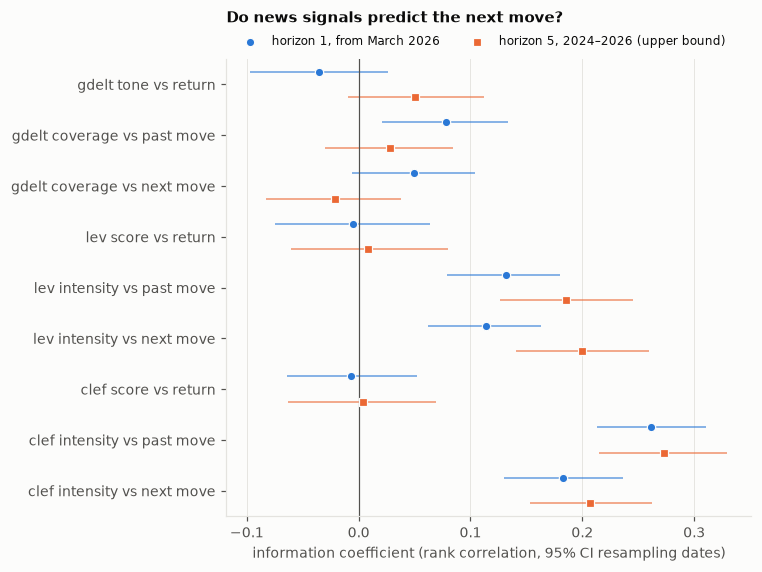

In [8]:
def signals(horizon: int) -> pd.DataFrame:
    rows = []
    for s in SERIES:
        close = s.df["close"].to_numpy()
        for i in POINTS[horizon][s.key]:
            until = pd.Timestamp(s.available_at()[i])
            f = FEED.features(s.key, until)
            rows.append({"series": s.key, "t": s.df["t"].iloc[i], "until": until, "gdelt tone": f["tone"],
                         "gdelt coverage": f["coverage"], "return": np.log(close[i + horizon] / close[i]),
                         "past size": abs(np.log(close[i] / close[i - horizon]))})
    d = pd.DataFrame(rows).assign(size=lambda d: d["return"].abs())
    for model, sc in scores.items():
        d = d.merge(sc[["series", "until", "score", "intensity"]].rename(
            columns={"score": f"{model} score", "intensity": f"{model} intensity"}), on=["series", "until"], how="left")
    return d


WINDOWS = {1: "horizon 1, from March 2026", HORIZON: "horizon 5, 2024–2026 (upper bound)"}
SIG = {h: signals(h) for h in WINDOWS}
rows = []
for h, window in WINDOWS.items():
    d = SIG[h]
    for col in d.columns:
        if col.endswith(("score", "tone")):
            rows.append({"window": window, "signal": col, "against": "return", **rank_ic(d, col, "return")})
        elif col.endswith(("coverage", "intensity")):
            rows.append({"window": window, "signal": col, "against": "size of the past move (control)",
                         **rank_ic(d, col, "past size")})
            rows.append({"window": window, "signal": col, "against": "size of the next move", **rank_ic(d, col, "size")})
ic = pd.DataFrame(rows)
plots.dot_plot(ic.assign(label=ic["signal"] + " vs " + ic["against"].str.replace(" (control)", "", regex=False)
                          .str.replace("size of the ", "", regex=False)),
               y="label", x="ic", hue="window", lo="lo", hi="hi",
               xlabel="information coefficient (rank correlation, 95% CI resampling dates)",
               title="Do news signals predict the next move?", path=CHARTS / "03_news_ic.png")
ic.set_index(["window", "signal", "against"])

By asset class, horizon 1 (the main window):

In [9]:
d1 = SIG[1].assign(asset_class=lambda d: d["series"].map(ASSET_CLASS))
pd.DataFrame({cls: {col: rank_ic(g, col, "return", n=500)["ic"] for col in d1.columns if col.endswith(("score", "tone"))}
              for cls, g in d1.groupby("asset_class")}).T

,gdelt tone,lev score,clef score
commodity,-0.111,-0.049,-0.012
crypto,0.003,0.049,0.009
equity,-0.027,-0.055,-0.109
fx,-0.080,-0.060,-0.047


### Is intensity more than volatility?

Both readers' intensity rises with the size of the next move, but the pooled IC mixes two things that need no news to predict: instruments differ in volatility (crypto moves more than the euro, and its headlines are rated more intensely), and large moves follow large moves. Two stricter tests remove them: the IC of percentile ranks taken within each instrument, and the IC with the part of the next move's size that the past move's size and the trailing 60-observation volatility leave unexplained (a regression on ranks, per instrument).

In [11]:
SIZE_SIGNALS = ["gdelt coverage", *(f"{m} intensity" for m in scores)]


def unexplained_size(d: pd.DataFrame, window: int = 60) -> pd.DataFrame:
    """Per instrument: percentile ranks, and the next move's size rank left after the past move's size and trailing volatility."""
    vol = pd.concat([pd.DataFrame({"series": s.key, "t": s.df["t"],
                                   "trailing vol": np.log(s.df["close"]).diff().rolling(window).std()}) for s in SERIES])
    d = d.merge(vol, on=["series", "t"]).dropna(subset=["trailing vol"])
    out = []
    for _, g in d.groupby("series"):
        g = g.assign(**{c: g[c].rank(pct=True) for c in [*SIZE_SIGNALS, "size", "past size", "trailing vol"]})
        X = np.column_stack([np.ones(len(g)), g["past size"], g["trailing vol"]])
        out.append(g.assign(unexplained=g["size"] - X @ np.linalg.lstsq(X, g["size"], rcond=None)[0]))
    return pd.concat(out)


rows = []
for h, window in WINDOWS.items():
    w = unexplained_size(SIG[h])
    for col in SIZE_SIGNALS:
        rows.append({"window": window, "signal": col, "against": "size of the next move, within instrument",
                     **rank_ic(w, col, "size")})
        rows.append({"window": window, "signal": col, "against": "beyond the past move and trailing volatility",
                     **rank_ic(w, col, "unexplained")})
controls = pd.DataFrame(rows)

# the part 2 result in one chart: direction of the next move, the positive control, intensity within instrument
reader_ic = pd.concat([
    ic[ic["against"] == "return"].assign(label=lambda d: d["signal"] + " vs next return"),
    ic[ic["signal"].str.endswith("intensity") & ic["against"].str.startswith("size of the past")]
    .assign(label=lambda d: d["signal"] + " vs past move size"),
    controls[controls["signal"].str.endswith("intensity") & controls["against"].str.endswith("within instrument")]
    .assign(label=lambda d: d["signal"] + " vs next move size, within instrument"),
])
plots.dot_plot(reader_ic, y="label", x="ic", hue="window", lo="lo", hi="hi",
               xlabel="information coefficient (rank correlation, 95% CI resampling dates)",
               title="Headline readers: what moved, not what moves next", path=CHARTS / "04_reader_ic.png")
controls.set_index(["window", "signal", "against"])

ic     lo    hi     N  dates
window                             signal         against                                                                     
horizon 1, from March 2026         gdelt coverage size of the next move, within instrument     0.033 -0.028 0.092  1293    213
                                                  beyond the past move and trailing volatility 0.026 -0.034 0.086  1293    213
                                   lev intensity  size of the next move, within instrument     0.008 -0.050 0.062  1293    213
                                                  beyond the past move and trailing volatility 0.013 -0.044 0.068  1293    213
                                   clef intensity size of the next move, within instrument     0.040 -0.018 0.103  1293    213
                                                  beyond the past move and trailing volatility 0.042 -0.018 0.103  1293    213
horizon 5, 2024–2026 (upper bound) gdelt coverage size of the next move, within instrument     0.034 -0.024 0.089  1193    386
                                                  beyond the past move and trailing volatility 0.032 -0.025 0.087  1193    386
                                   lev intensity  size of the next move, within instrument     0.063  0.012 0.117  1198    388
                                                  beyond the past move and trailing volatility 0.068  0.015 0.121  1198    388
                                   clef intensity size of the next move, within instrument     0.072  0.012 0.128  1198    388
                                                  beyond the past move and trailing volatility 0.066  0.008 0.121  1198    388

### Part 2 conclusions

**The news score does not predict returns, as expected.** At horizon 1 from March 2026 the IC of lev's score is −0.005 (−0.075 to +0.064) and clef's −0.007 (−0.064 to +0.053), on 1,293 decision points over 213 dates; GDELT's own tone does no better (−0.035, −0.097 to +0.026). The horizon-5 window over 2024–2026, which the models may have seen in training, gives the same picture (+0.008 and +0.003). By asset class the ICs are small and mostly negative, with no class standing out consistently across signals. By the rule stated before the run, the score is not tried as a TimesFM covariate.

**The method can find a relationship where one exists.** The readers' intensity (how strongly they rate the headlines, either way) tracks the size of the move *before* the decision: IC +0.132 (+0.079 to +0.180) for lev and +0.261 (+0.213 to +0.311) for clef at horizon 1, pooled over instruments, well above GDELT coverage (+0.078). The readers recognise news about large moves; the news simply says nothing about the direction of the next one.

**Intensity's link to the next move's size is mostly volatility the price already shows.** Pooled, intensity also rises with the size of the next move (+0.114 for lev, +0.183 for clef at horizon 1), but within each instrument this falls to +0.008 (−0.050 to +0.062) and +0.040 (−0.018 to +0.103): most of the pooled figure is that volatile instruments have more intense headlines. Over 2024–2026 at horizon 5 a small part survives the past move and trailing volatility (+0.068 for lev, +0.066 for clef, lower bounds about +0.01), but not in the main window, and that period may be in the models' training data. It is a weak lead for volatility forecasting, not a finding.

**Overall, the decision models add nothing to TimesFM in either role tested here.** As members of a combination they bring diversity without skill; as headline readers they understand what the news is about, but the direction it points to is already in the price.